# Exploration: redshift-dependent UVJ wedge (Whitaker et al. 2011, Eqs. 14-15)

**Not used in the paper.** The paper currently classifies quiescent galaxies with one fixed wedge at all redshifts. Here the full-sample results are recomputed with the redshift-dependent selection of Whitaker et al. (2011, ApJ 735, 86), to see how much the conclusions change. All outputs go to `outputs/useall/whitaker_wedge/`; nothing existing is overwritten.

**Whitaker et al. (2011) quiescent selection**

- Diagonal: $U-V > 0.88\,(V-J) + 0.69$ for $z<0.5$; $+\,0.59$ for $z>0.5$ (Eq. 14).
- Box limits (Eq. 15): $U-V>1.3,\ V-J<1.6$ for $0<z<1.5$; $U-V>1.3,\ V-J<1.5$ for $1.5<z<2.0$; $U-V>1.2,\ V-J<1.4$ for $2.0<z<3.5$.
- The selection is defined only to $z<3.5$, so the comparison below is restricted to $z<3.5$. Non-quiescent galaxies are split into star-forming / dusty at $V-J=1.2$ exactly as in the paper (not part of Whitaker's definition).

The fixed wedge compared against is the paper's: $U-V>1.3$, $V-J<1.6$, $U-V>0.867(V-J)+0.563$.

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
from src import config
from glass import photometry, visualization

plt.style.use('default')
visualization.apply_pasa_style()
OUT = os.path.join(config.PROCESSED_DATA_DIR, 'useall', 'whitaker_wedge')
os.makedirs(OUT, exist_ok=True)
DATA = os.path.join('..', 'datasets', 'full_zfourge_decomposed')
rng = np.random.default_rng(42)
N_BOOT = 2000
FL = r'$f_{\rm AGN}$'


def classify_whitaker(vj, uv, z):
    # Whitaker et al. (2011) Eqs. 14-15. Returns 0 = quiescent, 1 = star-forming, 2 = dusty, -1 = outside z range (z >= 3.5).
    vj, uv, z = np.asarray(vj, float), np.asarray(uv, float), np.asarray(z, float)
    c = np.where(z < 0.5, 0.69, 0.59)
    uv_min = np.where(z < 2.0, 1.3, np.where(z < 3.5, 1.2, np.nan))
    vj_max = np.where(z < 1.5, 1.6, np.where(z < 2.0, 1.5, np.where(z < 3.5, 1.4, np.nan)))
    quiescent = (uv > 0.88 * vj + c) & (uv > uv_min) & (vj < vj_max)
    cls = np.where(quiescent, 0, np.where(vj <= 1.2, 1, 2))
    return np.where(z >= 3.5, -1, cls)

## 1. Load the full-sample colours and classify with both wedges

In [2]:
tab = pd.read_csv(os.path.join(DATA, 'zfourge_useall_uvj.csv'))
tab = tab.dropna(subset=['UV_Full', 'VJ_Full', 'UV_Decomposed', 'VJ_Decomposed']).copy()
z = tab['zpk'].values
tab['fx_full'] = photometry.classify_uvj(tab['VJ_Full'].values, tab['UV_Full'].values)          # paper's fixed wedge
tab['fx_dec'] = photometry.classify_uvj(tab['VJ_Decomposed'].values, tab['UV_Decomposed'].values)
tab['wh_full'] = classify_whitaker(tab['VJ_Full'], tab['UV_Full'], z)                             # Whitaker et al. 2011
tab['wh_dec'] = classify_whitaker(tab['VJ_Decomposed'], tab['UV_Decomposed'], z)

s = tab[tab['zpk'] < 3.5].copy()                                  # Whitaker's wedge is defined to z < 3.5
print(f"galaxies with colours: {len(tab)}; at z < 3.5 (used below): {len(s)}")
a = s[s['fracAGN'] > 0].copy()                                    # potential-AGN galaxies
print(f"potential-AGN galaxies at z < 3.5: {len(a)}")

z_bins = [(0, 0.5), (0.5, 1.0), (1.0, 1.5), (1.5, 2.0), (2.0, 3.5)]

galaxies with colours: 37541; at z < 3.5 (used below): 35211
potential-AGN galaxies at z < 3.5: 22994


## 2. Quiescent fraction before and after decomposition, by redshift, under both wedges

In [3]:
rows = []
def add(label, sub):
    r = {'z_bin': label, 'N': len(sub)}
    for tag, cf, cd in [('fixed', 'fx_full', 'fx_dec'), ('Whitaker', 'wh_full', 'wh_dec')]:
        qf, qd = (sub[cf] == 0).mean() * 100, (sub[cd] == 0).mean() * 100
        r[f'{tag}: Q full %'] = round(qf, 2); r[f'{tag}: Q host %'] = round(qd, 2); r[f'{tag}: change pp'] = round(qd - qf, 2)
        r[f'{tag}: become Q'] = int(((sub[cf] != 0) & (sub[cd] == 0)).sum())
        r[f'{tag}: leave Q'] = int(((sub[cf] == 0) & (sub[cd] != 0)).sum())
    rows.append(r)
add('all z<3.5', s)
add('z<=1.5', s[s['zpk'] <= 1.5])
for lo, hi in z_bins:
    add(f'{lo}-{hi}', s[(s['zpk'] >= lo) & (s['zpk'] < hi)])
qtab = pd.DataFrame(rows)
qtab.to_csv(os.path.join(OUT, 'whitaker_vs_fixed_quiescent_fractions.csv'), index=False)
pd.set_option('display.width', 250)
print(qtab.to_string(index=False))

    z_bin     N  fixed: Q full %  fixed: Q host %  fixed: change pp  fixed: become Q  fixed: leave Q  Whitaker: Q full %  Whitaker: Q host %  Whitaker: change pp  Whitaker: become Q  Whitaker: leave Q
all z<3.5 35211             5.84             8.79              2.95             1038               1                2.59                2.89                 0.30                 105                  0
   z<=1.5 20207            10.16            15.29              5.13             1036               0                4.48                4.97                 0.49                 100                  0
    0-0.5  3979            17.89            19.70              1.81               72               0                7.59                8.29                 0.70                  28                  0
  0.5-1.0  9770            12.37            19.14              6.77              661               0                6.08                6.69                 0.61                  60               

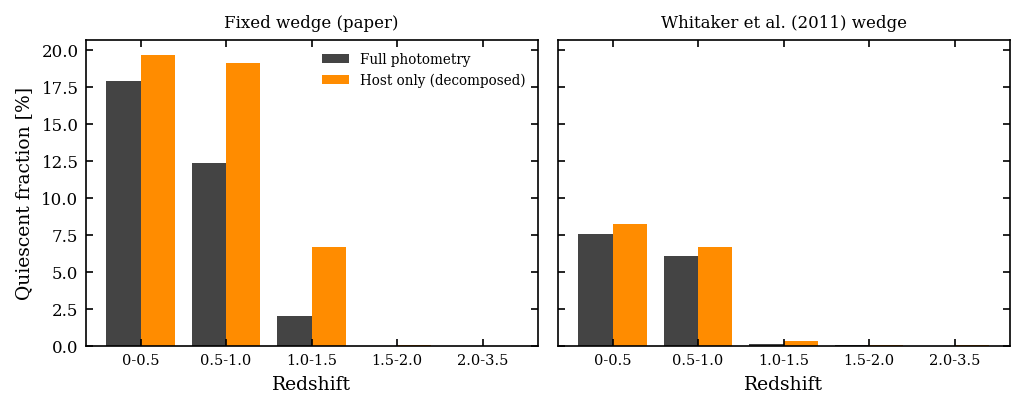

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(6.9, 2.8), sharey=True)
labels = [f'{lo}-{hi}' for lo, hi in z_bins]
x = np.arange(len(labels))
for ax, tag, title in [(axes[0], 'fixed', 'Fixed wedge (paper)'), (axes[1], 'Whitaker', 'Whitaker et al. (2011) wedge')]:
    full = [qtab.loc[qtab.z_bin == l, f'{tag}: Q full %'].iloc[0] for l in labels]
    host = [qtab.loc[qtab.z_bin == l, f'{tag}: Q host %'].iloc[0] for l in labels]
    ax.bar(x - 0.2, full, 0.4, color='#444444', label='Full photometry')
    ax.bar(x + 0.2, host, 0.4, color='darkorange', label='Host only (decomposed)')
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7)
    ax.set_xlabel('Redshift'); ax.set_title(title, fontsize=8)
axes[0].set_ylabel('Quiescent fraction [%]'); axes[0].legend(fontsize=6.5, frameon=False)
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'whitaker_vs_fixed_quiescent_fraction_by_z.pdf'), bbox_inches='tight')
plt.show()

## 3. Which galaxies migrate, and do the two wedges agree?

In [5]:
a['mv_fx'] = (a['fx_full'] != 0) & (a['fx_dec'] == 0)
a['mv_wh'] = (a['wh_full'] != 0) & (a['wh_dec'] == 0)
print('migrators (non-quiescent -> quiescent on removing the AGN), potential-AGN galaxies at z<3.5:')
print(f"  fixed wedge   : {int(a.mv_fx.sum())}")
print(f"  Whitaker wedge: {int(a.mv_wh.sum())}")
print(f"  in both: {int((a.mv_fx & a.mv_wh).sum())} | only fixed: {int((a.mv_fx & ~a.mv_wh).sum())} | only Whitaker: {int((~a.mv_fx & a.mv_wh).sum())}")
print('\nmigrators by redshift bin (fixed / Whitaker):')
for lo, hi in z_bins:
    t = a[(a.zpk >= lo) & (a.zpk < hi)]
    print(f"  z={lo}-{hi}: potential-AGN {len(t):5d} | fixed {int(t.mv_fx.sum()):4d} | Whitaker {int(t.mv_wh.sum()):4d}")
print('\nquiescent in FULL photometry at z>=1.5 (all galaxies, z<3.5): fixed %d | Whitaker %d' % (
    int(((s.zpk >= 1.5) & (s.fx_full == 0)).sum()), int(((s.zpk >= 1.5) & (s.wh_full == 0)).sum())))
hm = s[(s.zpk >= 1.5) & (s.lmass > 10.5)]
print('high-mass (log M>10.5) galaxies at 1.5<=z<3.5: N=%d | quiescent fixed %d | Whitaker %d (host-only: fixed %d | Whitaker %d)' % (
    len(hm), int((hm.fx_full == 0).sum()), int((hm.wh_full == 0).sum()), int((hm.fx_dec == 0).sum()), int((hm.wh_dec == 0).sum())))

migrators (non-quiescent -> quiescent on removing the AGN), potential-AGN galaxies at z<3.5:
  fixed wedge   : 1038
  Whitaker wedge: 105
  in both: 47 | only fixed: 991 | only Whitaker: 58

migrators by redshift bin (fixed / Whitaker):
  z=0-0.5: potential-AGN  1720 | fixed   72 | Whitaker   28
  z=0.5-1.0: potential-AGN  5141 | fixed  661 | Whitaker   60
  z=1.0-1.5: potential-AGN  3727 | fixed  303 | Whitaker   12
  z=1.5-2.0: potential-AGN  4204 | fixed    1 | Whitaker    0
  z=2.0-3.5: potential-AGN  8202 | fixed    1 | Whitaker    5

quiescent in FULL photometry at z>=1.5 (all galaxies, z<3.5): fixed 4 | Whitaker 6
high-mass (log M>10.5) galaxies at 1.5<=z<3.5: N=998 | quiescent fixed 1 | Whitaker 0 (host-only: fixed 2 | Whitaker 1)


## 4. Migration rate vs $f_{\rm AGN}$ under both wedges

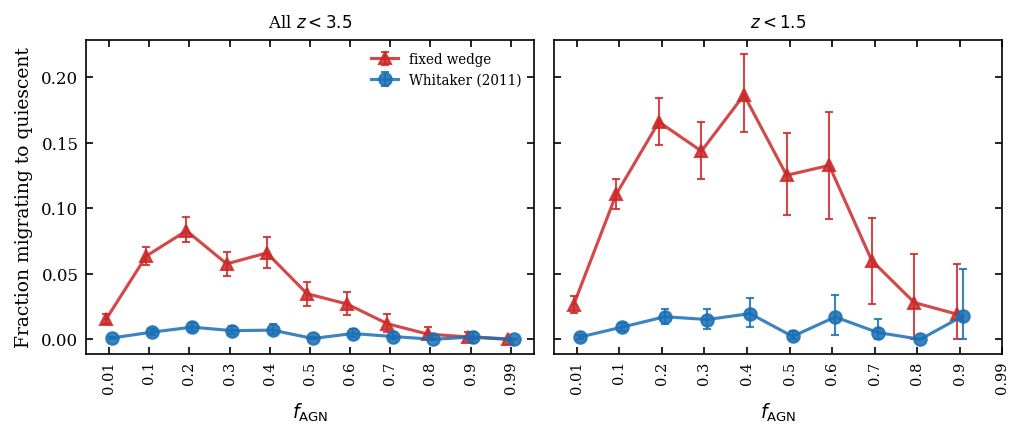

migration rate, z<1.5:
wedge  Whitaker (2011)  fixed wedge
f_AGN                              
0.01             0.002        0.026
0.10             0.009        0.111
0.20             0.017        0.166
0.30             0.015        0.144
0.40             0.020        0.187
0.50             0.002        0.125
0.60             0.017        0.133
0.70             0.005        0.060
0.80             0.000        0.028
0.90             0.018        0.019


In [6]:
def pooled(data, col):
    grid = sorted(data['fracAGN'].unique())
    mean, lo, hi, n = [], [], [], []
    for fv in grid:
        v = data.loc[data['fracAGN'] == fv, col].dropna().values.astype(float)
        n.append(len(v)); mean.append(v.mean())
        b = rng.choice(v, size=(N_BOOT, len(v)), replace=True).mean(axis=1)
        lo.append(np.percentile(b, 2.5)); hi.append(np.percentile(b, 97.5))
    return grid, np.array(mean), np.array(lo), np.array(hi), np.array(n)

GRID = sorted(a['fracAGN'].unique())
fig, axes = plt.subplots(1, 2, figsize=(6.9, 3.0), sharey=True)
out_rows = []
for ax, (title, sel) in zip(axes, [('All $z<3.5$', lambda d: d), (r'$z<1.5$', lambda d: d[d.zpk < 1.5])]):
    for tag, mvcol, riskcol, color, mk in [('fixed wedge', 'mv_fx', 'fx_full', '#CC2929', '^'), ('Whitaker (2011)', 'mv_wh', 'wh_full', '#1A6FB5', 'o')]:
        risk = sel(a[a[riskcol] != 0]).copy()
        risk['moved'] = risk[mvcol].astype(float)
        g, m, lo, hi, n = pooled(risk, 'moved')
        pos = np.array([GRID.index(v) for v in g]) + (0.07 if mk == 'o' else -0.07)
        ax.errorbar(pos, m, yerr=[m - lo, hi - m], fmt=mk + '-', color=color, ecolor=color, elinewidth=1, capsize=2, label=tag, alpha=0.85)
        out_rows.append(pd.DataFrame({'sample': title, 'wedge': tag, 'f_AGN': g, 'N_at_risk': n, 'rate': m, 'ci_lo': lo, 'ci_hi': hi}))
    ax.set_xticks(np.arange(len(GRID))); ax.set_xticklabels([f'{v:g}' for v in GRID], rotation=90, fontsize=7)
    ax.set_xlabel(FL); ax.set_title(title, fontsize=8)
axes[0].set_ylabel('Fraction migrating to quiescent'); axes[0].legend(fontsize=6.5, frameon=False)
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'whitaker_vs_fixed_migration_vs_fAGN.pdf'), bbox_inches='tight')
plt.show()
mig = pd.concat(out_rows); mig.to_csv(os.path.join(OUT, 'whitaker_vs_fixed_migration_vs_fAGN.csv'), index=False)
piv = mig[mig['sample'] == r'$z<1.5$'].pivot(index='f_AGN', columns='wedge', values='rate').round(3)
print('migration rate, z<1.5:'); print(piv.to_string())

## 5. Re-adding the AGN: class recovery of the migrators under the Whitaker wedge

In [7]:
rec = pd.read_csv(os.path.join(DATA, 'zfourge_useall_recombined.csv'))
h = a.merge(rec, on='ID', how='inner')
rows = []
for m in ['Type1', 'Type2', 'Matched']:
    ok = h[f'UV_rec_{m}'].notna() & h[f'VJ_rec_{m}'].notna()
    cls_rec = classify_whitaker(h[f'VJ_rec_{m}'].fillna(0), h[f'UV_rec_{m}'].fillna(0), h['zpk'].values)
    cls_rec_fx = photometry.classify_uvj(h[f'VJ_rec_{m}'].fillna(0).values, h[f'UV_rec_{m}'].fillna(0).values)
    for tag, mvcol, fullcol, rc in [('fixed', 'mv_fx', 'fx_full', cls_rec_fx), ('Whitaker', 'mv_wh', 'wh_full', cls_rec)]:
        sel = ok & h[mvcol]
        hit = (rc[sel.values] == h.loc[sel, fullcol].values).astype(float)
        b = rng.choice(hit, size=(N_BOOT, len(hit)), replace=True).mean(axis=1)
        all_hit = (rc[ok.values] == h.loc[ok, fullcol].values).mean()
        rows.append({'template': m, 'wedge': tag, 'migrators n': int(sel.sum()), 'migrators recovered': round(hit.mean(), 3),
                     'ci_lo': round(np.percentile(b, 2.5), 3), 'ci_hi': round(np.percentile(b, 97.5), 3), 'all potential-AGN recovered': round(all_hit, 3)})
rtab = pd.DataFrame(rows)
rtab.to_csv(os.path.join(OUT, 'whitaker_vs_fixed_recombination_recovery.csv'), index=False)
print(rtab.to_string(index=False))
base_fx = (h.fx_full == h.fx_dec).mean(); base_wh = (h.wh_full == h.wh_dec).mean()
print(f"\n'do nothing' baseline (class unchanged by decomposition): fixed {base_fx:.3f} | Whitaker {base_wh:.3f}")

template    wedge  migrators n  migrators recovered  ci_lo  ci_hi  all potential-AGN recovered
   Type1    fixed         1038                0.980  0.970  0.987                        0.957
   Type1 Whitaker          105                0.571  0.476  0.667                        0.969
   Type2    fixed         1038                0.015  0.009  0.024                        0.931
   Type2 Whitaker          105                0.010  0.000  0.029                        0.972
 Matched    fixed         1038                0.981  0.972  0.988                        0.967
 Matched Whitaker          105                0.571  0.467  0.667                        0.971

'do nothing' baseline (class unchanged by decomposition): fixed 0.933 | Whitaker 0.974


## 6. Demographics of the migrators ($z\leq1.5$) under both wedges

In [8]:
cat = s.merge(a[['ID', 'mv_fx', 'mv_wh']], on='ID', how='left')
cat = cat[(cat.zpk <= 1.5) & cat.lmass.notna() & cat.lssfr.notna()]
rows = []
for tag, mv, qcol in [('fixed', 'mv_fx', 'fx_full'), ('Whitaker', 'mv_wh', 'wh_full')]:
    sub = cat[(cat.fracAGN > 0)]
    for name, g in [('migrators', sub[sub[mv] == True]),
                    ('already quiescent in full phot.', sub[sub[qcol] == 0]),
                    ('at risk, do not migrate', sub[(sub[qcol] != 0) & (sub[mv] != True)])]:
        rows.append({'wedge': tag, 'group': name, 'n': len(g), 'median log M': round(g.lmass.median(), 2), 'median log sSFR': round(g.lssfr.median(), 2)})
dtab = pd.DataFrame(rows)
dtab.to_csv(os.path.join(OUT, 'whitaker_vs_fixed_demographics.csv'), index=False)
print(dtab.to_string(index=False))

   wedge                           group    n  median log M  median log sSFR
   fixed                       migrators 1023          9.41            -9.93
   fixed already quiescent in full phot.  959          9.41           -10.54
   fixed         at risk, do not migrate 8500          8.72            -9.19
Whitaker                       migrators  100          9.89           -10.11
Whitaker already quiescent in full phot.  505          9.77           -10.72
Whitaker         at risk, do not migrate 9877          8.79            -9.22


## 7. Why the result is so sensitive: where the migrators sit relative to the two boundaries

Host-only (decomposed) UVJ positions of the galaxies that migrate under the paper's fixed wedge, for two redshift ranges, with both quiescent boundaries drawn. Points are coloured by whether the galaxy is also a migrator under the Whitaker et al. (2011) wedge.

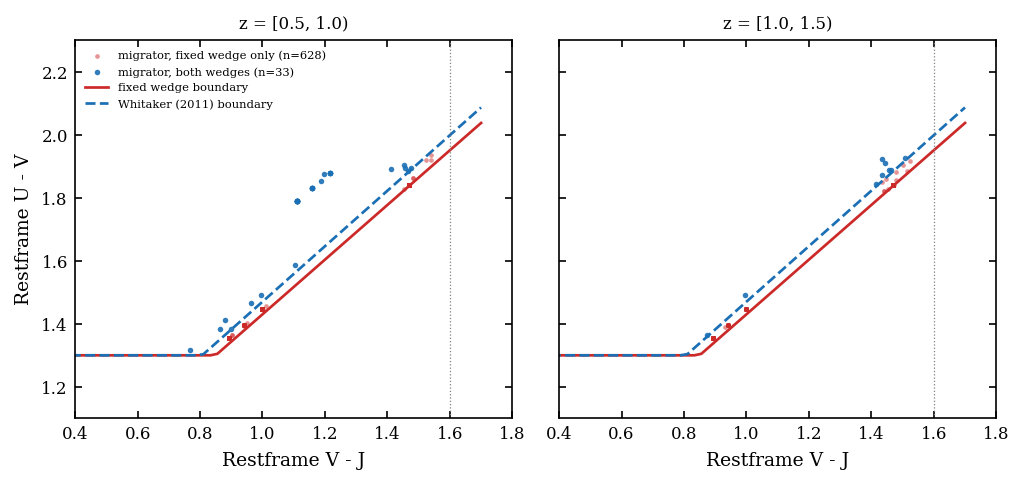

z=0.5-1.0: fixed-wedge migrators n=661; host-only U-V minus the Whitaker boundary: median -0.020 mag, 95% lie below the Whitaker boundary
z=1.0-1.5: fixed-wedge migrators n=303; host-only U-V minus the Whitaker boundary: median -0.022 mag, 97% lie below the Whitaker boundary


In [9]:
from matplotlib.patches import Polygon
fig, axes = plt.subplots(1, 2, figsize=(6.9, 3.3), sharex=True, sharey=True)
for ax, (lo, hi, c_wh) in zip(axes, [(0.5, 1.0, 0.59), (1.0, 1.5, 0.59)]):
    sub = a[(a.zpk >= lo) & (a.zpk < hi) & a.mv_fx]
    both = sub[sub.mv_wh]; only_fx = sub[~sub.mv_wh]
    ax.scatter(only_fx.VJ_Decomposed, only_fx.UV_Decomposed, s=5, c='#CC2929', alpha=0.5, lw=0, label=f'migrator, fixed wedge only (n={len(only_fx)})')
    ax.scatter(both.VJ_Decomposed, both.UV_Decomposed, s=7, c='#1A6FB5', alpha=0.9, lw=0, label=f'migrator, both wedges (n={len(both)})')
    vj = np.linspace(-0.5, 1.7, 100)
    # paper's fixed wedge boundary
    ax.plot(vj, np.maximum(1.3, 0.867 * vj + 0.563), color='#CC2929', lw=1.3, label='fixed wedge boundary')
    # Whitaker (2011) boundary for this redshift range
    ax.plot(vj, np.maximum(1.3, 0.88 * vj + c_wh), color='#1A6FB5', lw=1.3, ls='--', label='Whitaker (2011) boundary')
    ax.axvline(1.6, color='grey', lw=0.6, ls=':')
    ax.set_xlim(0.4, 1.8); ax.set_ylim(1.1, 2.3)
    ax.set_xlabel('Restframe V - J'); ax.set_title(f'z = [{lo}, {hi})', fontsize=8)
axes[0].set_ylabel('Restframe U - V')
axes[0].legend(fontsize=5.5, loc='upper left', frameon=False)
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'whitaker_vs_fixed_boundary_and_migrators.pdf'), bbox_inches='tight')
plt.show()
for lo, hi in [(0.5, 1.0), (1.0, 1.5)]:
    sub = a[(a.zpk >= lo) & (a.zpk < hi) & a.mv_fx]
    gap = sub.UV_Decomposed - np.maximum(1.3, 0.88 * sub.VJ_Decomposed + 0.59)
    print(f'z={lo}-{hi}: fixed-wedge migrators n={len(sub)}; host-only U-V minus the Whitaker boundary: median {gap.median():+.3f} mag, '
          f'{100 * (gap < 0).mean():.0f}% lie below the Whitaker boundary')

## 8. How much of the difference is the slope, the intercept, or the redshift dependence?

At $z\leq1.5$ both selections use the same box limits ($U-V>1.3$, $V-J<1.6$), so only the diagonal differs. Variants of the diagonal are compared (paper: slope 0.867, intercept 0.563; Whitaker: slope 0.88, intercept 0.59 at $z>0.5$ and 0.69 at $z<0.5$), and then the diagonal intercept of the paper's wedge is shifted by a small amount $\delta$ to show how steeply the result depends on the boundary position.

In [10]:
def classify_line(vj, uv, slope, intercept):
    q = (uv > slope * vj + intercept) & (uv > 1.3) & (vj < 1.6)
    return np.where(q, 0, np.where(vj <= 1.2, 1, 2))

lo = a[a.zpk <= 1.5].copy()
allz = s[s.zpk <= 1.5]

def count(slope, intercept):
    cf = classify_line(a_lo_vjf, a_lo_uvf, slope, intercept); cd = classify_line(a_lo_vjd, a_lo_uvd, slope, intercept)
    mig = int(((cf != 0) & (cd == 0)).sum())
    qf = classify_line(allz.VJ_Full.values, allz.UV_Full.values, slope, intercept)
    qd = classify_line(allz.VJ_Decomposed.values, allz.UV_Decomposed.values, slope, intercept)
    return mig, 100 * (qf == 0).mean(), 100 * (qd == 0).mean()

a_lo_vjf, a_lo_uvf = lo.VJ_Full.values, lo.UV_Full.values
a_lo_vjd, a_lo_uvd = lo.VJ_Decomposed.values, lo.UV_Decomposed.values

variants = [
    ('paper wedge (0.867, 0.563)', 0.867, 0.563),
    ('slope only -> 0.88', 0.88, 0.563),
    ('intercept only -> 0.59', 0.867, 0.59),
    ('Whitaker z>0.5 diagonal (0.88, 0.59)', 0.88, 0.59),
    ('Whitaker z<0.5 diagonal (0.88, 0.69)', 0.88, 0.69),
]
rows = []
for name, sl, ic in variants:
    mig, qf, qd = count(sl, ic)
    # mean boundary shift relative to the paper wedge over the V-J range where migrators sit (0.8-1.3)
    vjr = np.linspace(0.8, 1.3, 6)
    shift = float(np.mean((sl * vjr + ic) - (0.867 * vjr + 0.563)))
    rows.append({'diagonal': name, 'mean boundary shift (mag)': round(shift, 3), 'migrators (z<=1.5, potential-AGN)': mig,
                 'Q full %': round(qf, 2), 'Q host %': round(qd, 2), 'change pp': round(qd - qf, 2)})
abl = pd.DataFrame(rows)
abl.to_csv(os.path.join(OUT, 'whitaker_diagonal_ablation.csv'), index=False)
print(abl.to_string(index=False))

                            diagonal  mean boundary shift (mag)  migrators (z<=1.5, potential-AGN)  Q full %  Q host %  change pp
          paper wedge (0.867, 0.563)                      0.000                               1037     10.18     15.31       5.13
                  slope only -> 0.88                      0.014                                888      8.58     12.98       4.39
              intercept only -> 0.59                      0.027                                 85      4.72      5.14       0.42
Whitaker z>0.5 diagonal (0.88, 0.59)                      0.041                                 78      4.64      5.02       0.39
Whitaker z<0.5 diagonal (0.88, 0.69)                      0.141                                161      3.90      4.70       0.80


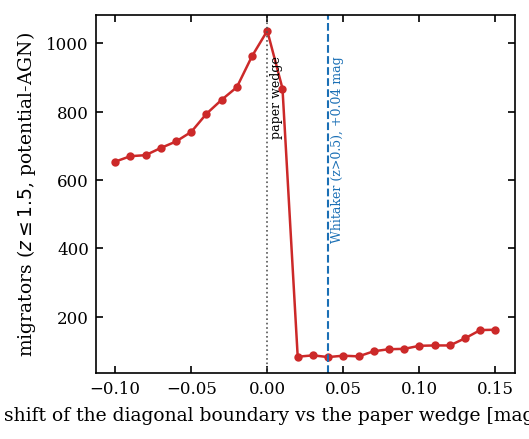

shift -0.05 mag:   741 migrators (71% of the paper-wedge count), change +3.67 pp
shift -0.02 mag:   872 migrators (84% of the paper-wedge count), change +4.32 pp
shift +0.00 mag:  1037 migrators (100% of the paper-wedge count), change +5.13 pp
shift +0.02 mag:    83 migrators (8% of the paper-wedge count), change +0.41 pp
shift +0.04 mag:    82 migrators (8% of the paper-wedge count), change +0.41 pp
shift +0.05 mag:    86 migrators (8% of the paper-wedge count), change +0.43 pp
shift +0.10 mag:   115 migrators (11% of the paper-wedge count), change +0.57 pp


In [11]:
deltas = np.round(np.arange(-0.10, 0.1501, 0.01), 3)
mig_curve, dq_curve = [], []
for d_ in deltas:
    mig, qf, qd = count(0.867, 0.563 + d_)
    mig_curve.append(mig); dq_curve.append(qd - qf)
mig_curve = np.array(mig_curve); dq_curve = np.array(dq_curve)
pd.DataFrame({'delta_intercept': deltas, 'migrators': mig_curve, 'change_pp': dq_curve}).to_csv(os.path.join(OUT, 'wedge_boundary_sensitivity.csv'), index=False)

fig, ax = plt.subplots(figsize=(3.6, 3.0))
ax.plot(deltas, mig_curve, 'o-', color='#CC2929', ms=3, lw=1.2)
ax.axvline(0, color='#555555', lw=0.8, ls=':'); ax.text(0.002, mig_curve.max() * 0.93, 'paper wedge', fontsize=6, rotation=90, va='top')
ax.axvline(0.04, color='#1A6FB5', lw=1.0, ls='--'); ax.text(0.042, mig_curve.max() * 0.93, 'Whitaker (z>0.5), +0.04 mag', fontsize=6, rotation=90, va='top', color='#1A6FB5')
ax.set_xlabel('shift of the diagonal boundary vs the paper wedge [mag in U-V]')
ax.set_ylabel(r'migrators ($z\leq1.5$, potential-AGN)')
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'whitaker_boundary_sensitivity.pdf'), bbox_inches='tight')
plt.show()
for d_ in (-0.05, -0.02, 0.0, 0.02, 0.04, 0.05, 0.10):
    i = int(np.argmin(abs(deltas - d_)))
    print(f'shift {d_:+.2f} mag: {mig_curve[i]:5d} migrators ({100 * mig_curve[i] / mig_curve[np.argmin(abs(deltas))]:.0f}% of the paper-wedge count), change {dq_curve[i]:+.2f} pp')

## 9. The host-only colours pile up right at the paper wedge's edge

The sensitivity in section 8 is a cliff, not a smooth trend. This section shows why: the host-only (decomposed) colours of the migrators fall on a handful of discrete values, a few hundredths of a magnitude above the paper wedge's diagonal.

migrators: 1036; distinct host-only (U-V, V-J) pairs: 58
most common host-only colour pairs among migrators:
uv      vj    
1.3550  0.8924    429
1.8400  1.4690    281
1.4472  0.9987    168
1.3962  0.9397     85
1.7903  1.1110     12
1.8294  1.1579      6
share of migrators in the 6 most common pairs: 95%


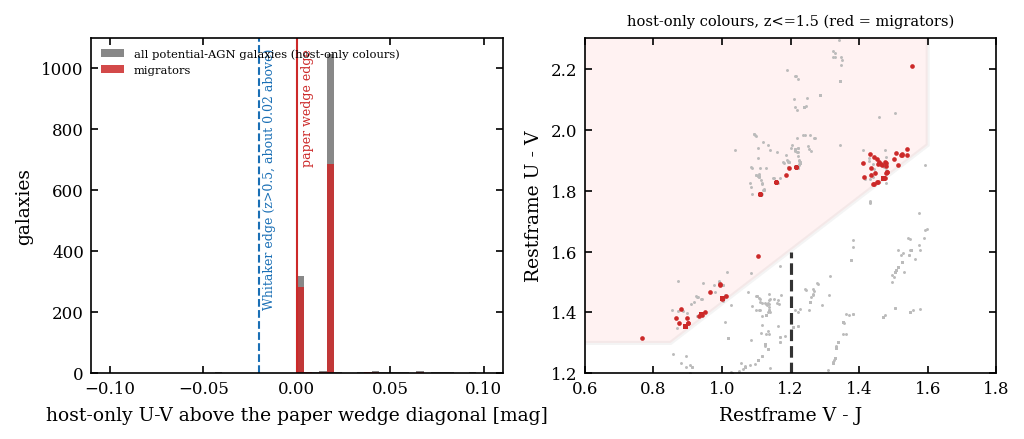

In [12]:
lo = a[(a.zpk <= 1.5)].copy()
g = lo[(lo.VJ_Decomposed > 0.85) & (lo.VJ_Decomposed < 1.6)].copy()
g['gap'] = g.UV_Decomposed - (0.867 * g.VJ_Decomposed + 0.563)       # signed distance above the paper wedge diagonal
g['gap_wh'] = g.UV_Decomposed - (0.88 * g.VJ_Decomposed + 0.59)      # signed distance above the Whitaker (z>0.5) diagonal
mig = lo[lo.mv_fx]
mg = mig.UV_Decomposed - (0.867 * mig.VJ_Decomposed + 0.563)

pairs = (mig.assign(uv=mig.UV_Decomposed.round(4), vj=mig.VJ_Decomposed.round(4)).groupby(['uv', 'vj']).size().sort_values(ascending=False))
print(f"migrators: {len(mig)}; distinct host-only (U-V, V-J) pairs: {len(pairs)}")
print('most common host-only colour pairs among migrators:')
print(pairs.head(6).to_string())
print(f"share of migrators in the 6 most common pairs: {100 * pairs.head(6).sum() / len(mig):.0f}%")

fig, axes = plt.subplots(1, 2, figsize=(6.9, 3.0))
ax = axes[0]
bins = np.arange(-0.10, 0.1001, 0.004)
ax.hist(g.gap, bins=bins, color='#888888', label='all potential-AGN galaxies (host-only colours)')
ax.hist(mg[(mg > -0.1) & (mg < 0.1)], bins=bins, color='#CC2929', alpha=0.85, label='migrators')
ax.axvline(0, color='#CC2929', lw=1.0); ax.text(0.002, ax.get_ylim()[1] * 0.97, 'paper wedge edge', color='#CC2929', fontsize=6, rotation=90, va='top')
ax.axvline(-0.02, color='#1A6FB5', lw=1.0, ls='--')
ax.text(-0.018, ax.get_ylim()[1] * 0.97, 'Whitaker edge (z>0.5, about 0.02 above)', color='#1A6FB5', fontsize=6, rotation=90, va='top')
ax.set_xlabel('host-only U-V above the paper wedge diagonal [mag]'); ax.set_ylabel('galaxies')
ax.legend(fontsize=5.5, frameon=False, loc='upper left')
ax = axes[1]
visualization.plot_uvj_diagram([], [], ax=ax, title='', show_region_labels=False)
ax.scatter(g.VJ_Decomposed, g.UV_Decomposed, s=2, c='#BBBBBB', lw=0, rasterized=True)
ax.scatter(mig.VJ_Decomposed, mig.UV_Decomposed, s=5, c='#CC2929', lw=0, rasterized=True)
ax.set_xlim(0.6, 1.8); ax.set_ylim(1.2, 2.3)
ax.set_title('host-only colours, z<=1.5 (red = migrators)', fontsize=7)
plt.tight_layout()
fig.savefig(os.path.join(OUT, 'migrator_pileup_at_wedge_edge.pdf'), bbox_inches='tight')
plt.show()